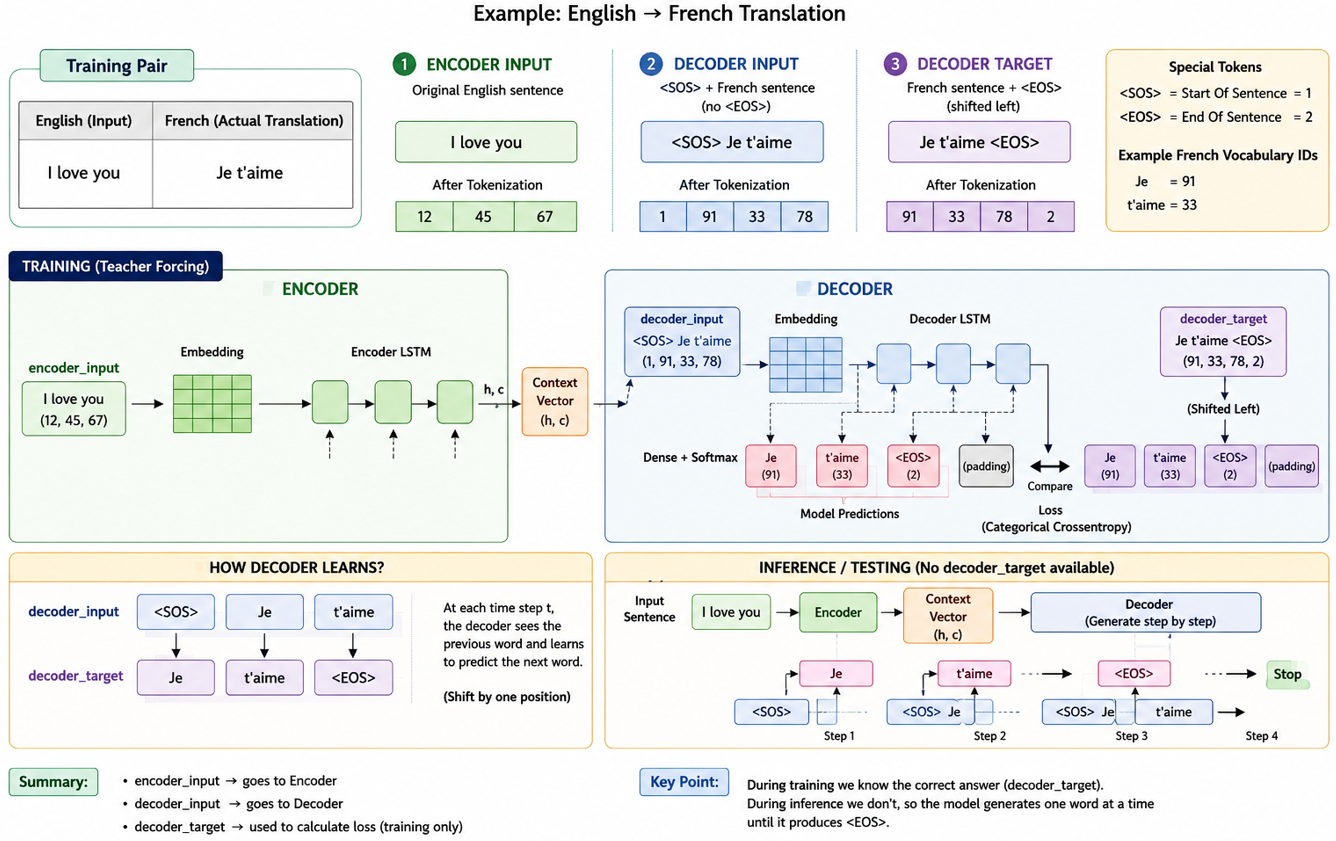

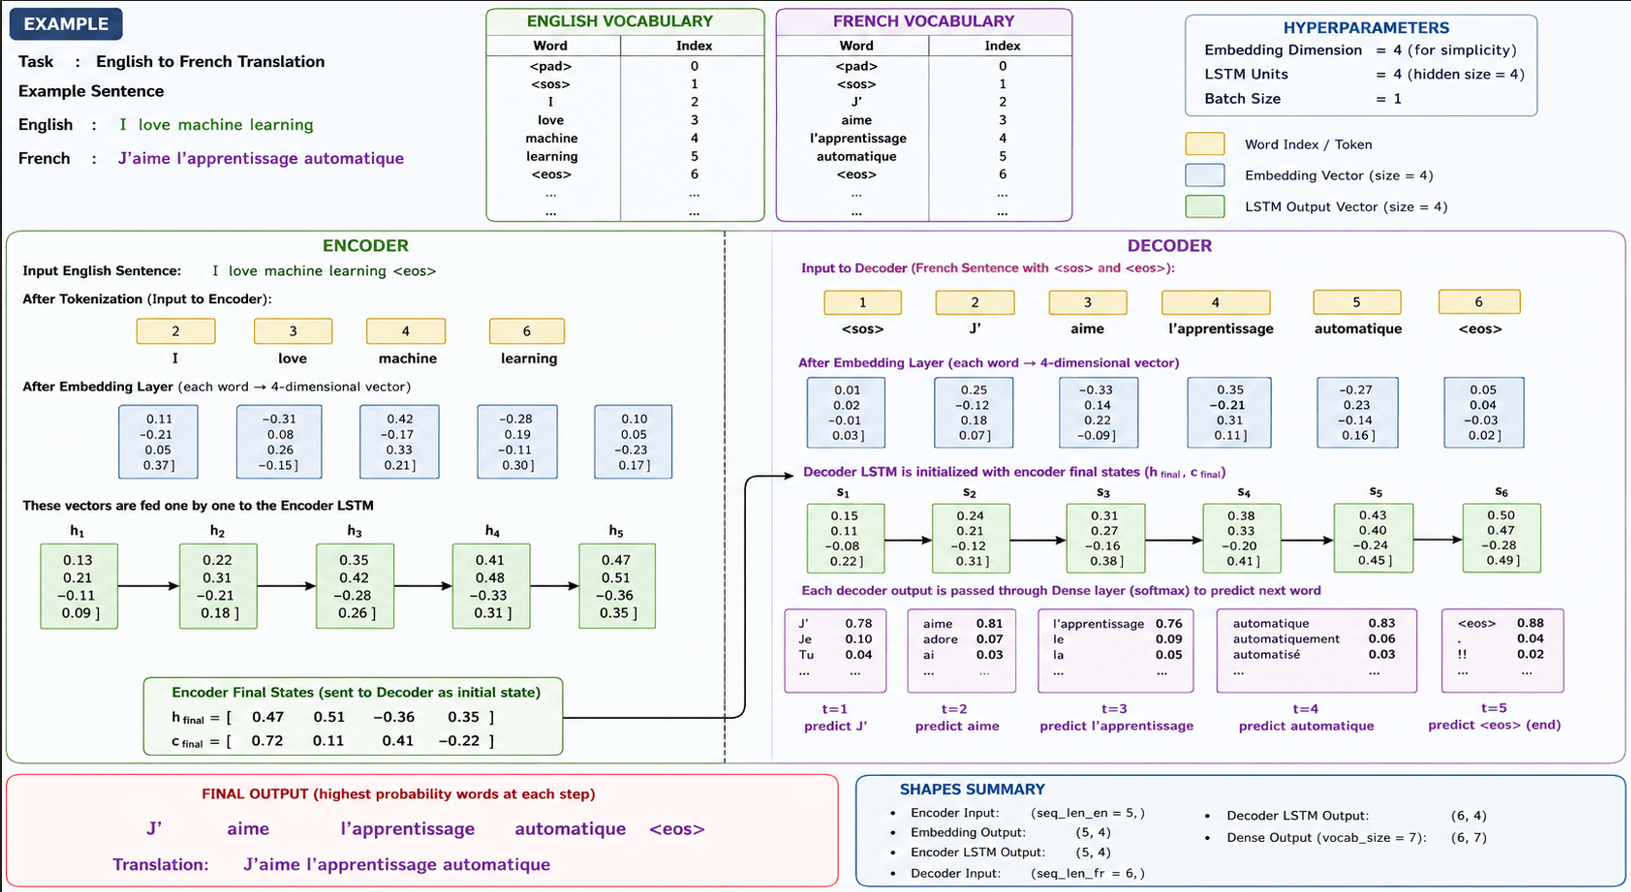

In [ ]:
# Dataset - https://drive.google.com/file/d/1pCy6DUw0krC59V_mN92BE8hJJYodYmle/view?usp=sharing

# Step 1 : Load Dataset

In [69]:
import pandas as pd

In [70]:
from os import name
df = pd.read_csv('/content/01-Jul_fra.txt', sep='\t',header=None,usecols=[0,1],names=['English','French'])
# os - operating system module -> help us to interact/ communicate with os
# name - specifc variable of operating system

In [71]:
df.head()

,English,French
0,Go.,Va !
1,Go.,Marche.
2,Go.,En route !
3,Go.,Bouge !
4,Hi.,Salut !


# Step 2 : Add Start and End Tokens

Why adding Add Start <sos> and End Tokens <eos> in French target column ?

Answer : Because the decoder needs to know,

 (i) where to start

(ii) where to stop

In [72]:
# ADD START AND END TOKENS
df['French'] = df['French'].apply(lambda x:"<sos> " + x + " <eos>")
# apply() -> modify every sentence of french column
# we are adding <start> and <end> to denote the starting and end of sequence

In [73]:
df.head()

,English,French
0,Go.,<sos> Va ! <eos>
1,Go.,<sos> Marche. <eos>
2,Go.,<sos> En route ! <eos>
3,Go.,<sos> Bouge ! <eos>
4,Hi.,<sos> Salut ! <eos>


In [74]:
# LET'S CHECK THE SHAPE
df.shape

(240521, 2)

In [75]:
df = df.iloc[:50000]

In [76]:
df.shape

(50000, 2)

In [77]:
import tensorflow as tf

print(tf.__version__)

2.20.0


# Step 3 : Create Tokenizers

In [78]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [79]:
eng_tokenizer = Tokenizer(filters="",oov_token="<unk>")
fre_tokenizer = Tokenizer(filters="",oov_token="<unk>")

Step 1: Create a Tokenizer object

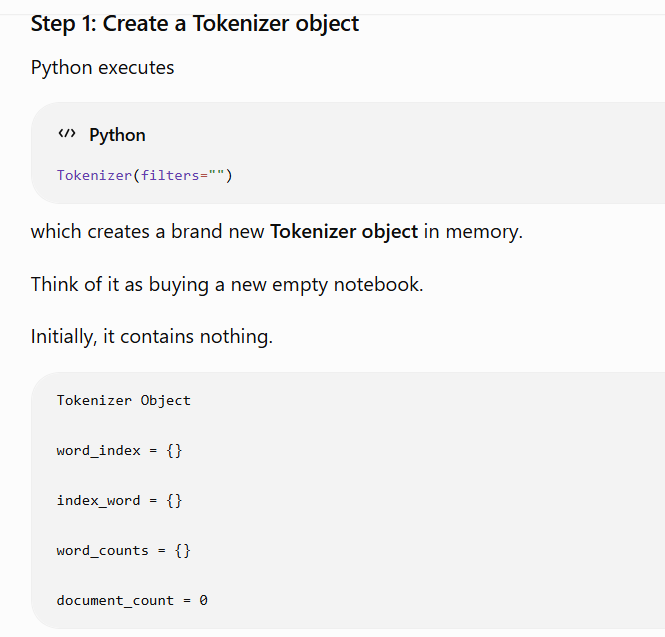

Step 2: Store its address in a variable


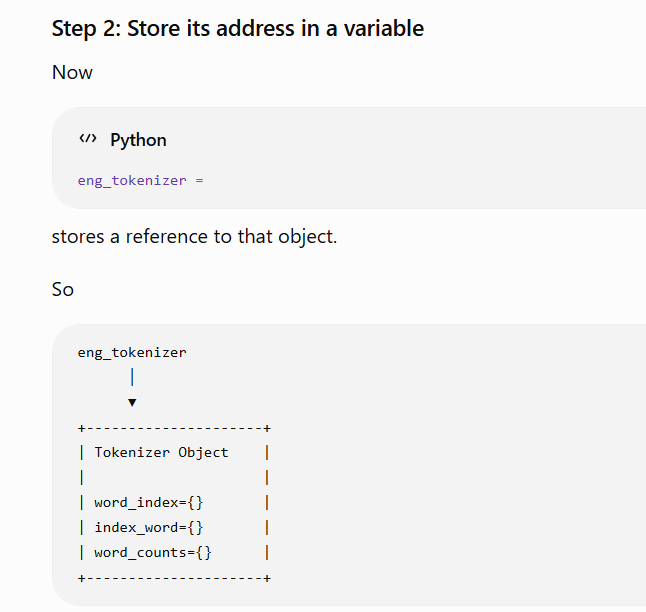

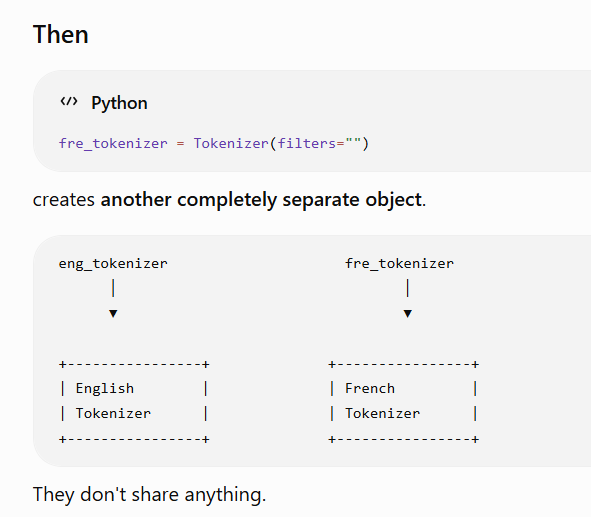

In [80]:
print(eng_tokenizer)

# Step 4 : Learn Vocabulary

In [81]:
eng_tokenizer.fit_on_texts(df['English'])

The actual learning happens with:

# *eng_tokenizer.fit_on_texts(df['English'])*

This is the step where the tokenizer builds its vocabulary (word_index, index_word, word_counts, etc.), Counts word frequencies

Imagine reading every English sentence. Learns vocabulary still no neural network yet.

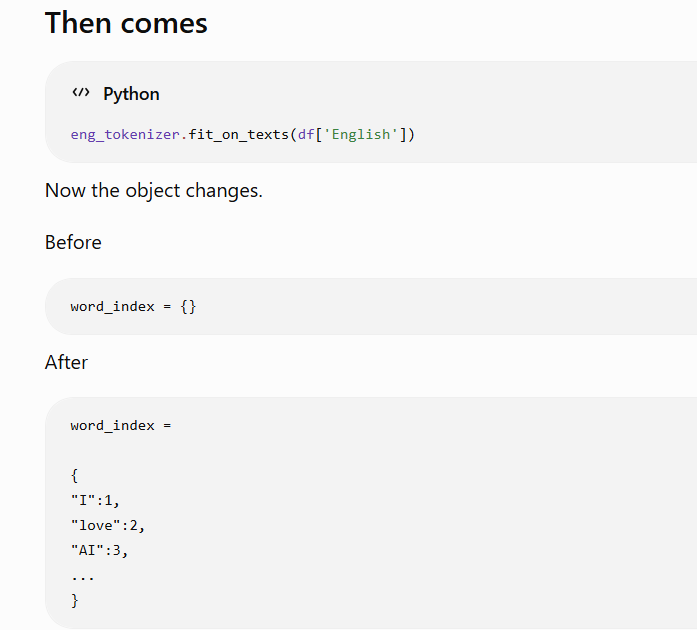

In [82]:
# We will get french token such as "possible\u202f!"" so following code will replace them with normal spaces.

df["French"] = (
    df["French"]
    .str.replace("\u202f", " ", regex=False)
    .str.replace("\xa0", " ", regex=False)
)

In below step, French vocabulary becomes

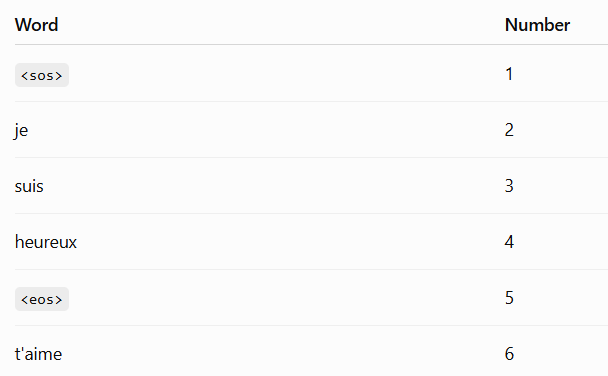

The tokenizer stores these mappings.

In [83]:
# Learns french vocabulary.
fre_tokenizer.fit_on_texts(df['French'])

In [84]:
eng_tokenizer.word_index

{'<unk>': 1,
 'i': 2,
 'you': 3,
 'a': 4,
 'is': 5,
 'tom': 6,
 'the': 7,
 "i'm": 8,
 'to': 9,
 'it': 10,
 'he': 11,
 "you're": 12,
 'was': 13,
 'do': 14,
 'we': 15,
 'are': 16,
 "don't": 17,
 'have': 18,
 'my': 19,
 'this': 20,
 'your': 21,
 "it's": 22,
 'it.': 23,
 'not': 24,
 'you.': 25,
 'can': 26,
 'did': 27,
 'be': 28,
 'that': 29,
 'they': 30,
 'me.': 31,
 'like': 32,
 "we're": 33,
 'me': 34,
 'what': 35,
 'no': 36,
 'all': 37,
 'very': 38,
 "that's": 39,
 'she': 40,
 'how': 41,
 'get': 42,
 'go': 43,
 'in': 44,
 'that.': 45,
 "can't": 46,
 'need': 47,
 "i'll": 48,
 'of': 49,
 'want': 50,
 'tom.': 51,
 'on': 52,
 'got': 53,
 'here.': 54,
 'know': 55,
 'for': 56,
 'just': 57,
 "they're": 58,
 'were': 59,
 'has': 60,
 'who': 61,
 'so': 62,
 'at': 63,
 "let's": 64,
 'love': 65,
 'take': 66,
 'this.': 67,
 "he's": 68,
 'look': 69,
 'it?': 70,
 'will': 71,
 'come': 72,
 'one': 73,
 'up.': 74,
 "didn't": 75,
 'too': 76,
 'let': 77,
 'had': 78,
 'why': 79,
 'go.': 80,
 'see': 81,
 'him

In [85]:
fre_tokenizer.word_index

{'<unk>': 1,
 '<sos>': 2,
 '<eos>': 3,
 'je': 4,
 '?': 5,
 'tom': 6,
 'pas': 7,
 'de': 8,
 'ne': 9,
 '!': 10,
 'est': 11,
 'vous': 12,
 'le': 13,
 'il': 14,
 'nous': 15,
 'suis': 16,
 "c'est": 17,
 "j'ai": 18,
 'la': 19,
 'à': 20,
 'un': 21,
 'tu': 22,
 'a': 23,
 'que': 24,
 'en': 25,
 'me': 26,
 'une': 27,
 'les': 28,
 'ce': 29,
 'ça': 30,
 'êtes': 31,
 'est-ce': 32,
 'tout': 33,
 'sommes': 34,
 'qui': 35,
 'sont': 36,
 'fait': 37,
 'es': 38,
 'elle': 39,
 'mon': 40,
 'ils': 41,
 'des': 42,
 "n'est": 43,
 'te': 44,
 'tom.': 45,
 'très': 46,
 'pas.': 47,
 'peux': 48,
 'elles': 49,
 'du': 50,
 'été': 51,
 'y': 52,
 'se': 53,
 'ça.': 54,
 'besoin': 55,
 'faire': 56,
 "l'air": 57,
 'était': 58,
 'votre': 59,
 'êtes-vous': 60,
 'comment': 61,
 'on': 62,
 'pour': 63,
 'ton': 64,
 'veux': 65,
 'personne': 66,
 'avons': 67,
 'ma': 68,
 "s'est": 69,
 'va': 70,
 'cela': 71,
 'où': 72,
 'faut': 73,
 "j'aime": 74,
 'monde': 75,
 'as': 76,
 'dans': 77,
 'au': 78,
 'pourquoi': 79,
 "c'était": 80,
 

# Step 5 : Based on the learnt Vocabulary, Convert Sentences into Numbers

Example :

I love AI

becomes

[5,12,20]

This is the Encoder Input.

In [86]:
# Convert text to Integer sequence
encoder_input = eng_tokenizer.texts_to_sequences(df['English'])

In [87]:
decoder_input = fre_tokenizer.texts_to_sequences(df['French'])

In [88]:
encoder_input

[[80],
 [80],
 [80],
 [80],
 [1437],
 [1437],
 [2067],
 [2067],
 [2067],
 [2067],
 [2067],
 [2067],
 [2067],
 [579],
 [579],
 [579],
 [579],
 [579],
 [579],
 [579],
 [4447],
 [2068],
 [2068],
 [2068],
 [3592],
 [3592],
 [3592],
 [4448],
 [3593],
 [3593],
 [1854],
 [1854],
 [3594],
 [2069],
 [2621],
 [2621],
 [2621],
 [3011],
 [3011],
 [3011],
 [368],
 [368],
 [368],
 [368],
 [1855],
 [1855],
 [43, 191],
 [43, 191],
 [43, 191],
 [4449],
 [4449],
 [2298],
 [2298],
 [2298],
 [2298],
 [2, 702],
 [2, 702],
 [2, 380],
 [2, 3012],
 [2, 3012],
 [2, 479],
 [4450, 6161],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [731],
 [3013],
 [3013],
 [916],
 [916],
 [916],
 [6162],
 [3595],
 [3595],
 [3595],
 [196, 23],
 [196, 23],
 [196, 23],
 [196, 23],
 [3014],
 [3014],
 [3014],
 [3014],
 [129, 23],
 [129, 23],
 [6163],
 [42, 74],
 [42, 74],
 [42, 74],
 [43, 88],
 [43, 88],
 [43, 88],
 [53, 322],
 [53, 322],
 [53, 322],
 [53, 70],
 [53, 70],
 [53, 70],
 [3596

In [89]:
decoder_input

[[2, 70, 10, 3],
 [2, 894, 3],
 [2, 25, 855, 10, 3],
 [2, 950, 10, 3],
 [2, 2047, 10, 3],
 [2, 5771, 3],
 [2, 1074, 10, 3],
 [2, 2971, 10, 3],
 [2, 200, 187, 2593, 20, 187, 4371, 10, 3],
 [2, 2594, 10, 3],
 [2, 3533, 10, 3],
 [2, 5772, 10, 3],
 [2, 5773, 10, 3],
 [2, 1074, 10, 3],
 [2, 2971, 10, 3],
 [2, 200, 187, 2593, 20, 187, 4371, 10, 3],
 [2, 2594, 10, 3],
 [2, 3533, 10, 3],
 [2, 5772, 10, 3],
 [2, 5773, 10, 3],
 [2, 35, 5, 3],
 [2, 30, 1691, 10, 3],
 [2, 8827, 10, 3],
 [2, 8828, 10, 3],
 [2, 20, 1847, 10, 3],
 [2, 8829, 10, 3],
 [2, 8830, 10, 3],
 [2, 78, 640, 10, 3],
 [2, 20, 1190, 10, 3],
 [2, 78, 5774, 10, 3],
 [2, 8831, 3],
 [2, 8832, 3],
 [2, 3534, 3],
 [2, 3534, 3],
 [2, 30, 856, 10, 3],
 [2, 8833, 10, 3],
 [2, 1848, 10, 3],
 [2, 494, 10, 3],
 [2, 604, 10, 3],
 [2, 2595, 3],
 [2, 494, 10, 3],
 [2, 604, 10, 3],
 [2, 5775, 3],
 [2, 2595, 3],
 [2, 4372, 3],
 [2, 2972, 3],
 [2, 8834, 3],
 [2, 8835, 3],
 [2, 8836, 3],
 [2, 2298, 10, 3],
 [2, 2047, 10, 3],
 [2, 2298, 10, 3],
 [2,

# Step 6 : Padding

Different sentences have different lengths.

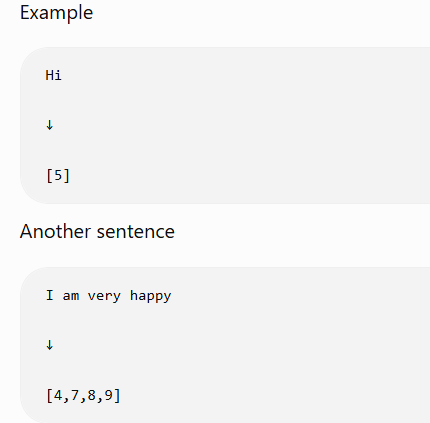

Neural networks require equal-length inputs.

So

pad_sequences(...)

makes them

[5,0,0,0]

[4,7,8,9]

Now every sentence has equal length.

In [90]:
# find the maximum length
max_len_eng = max(len(x) for x in encoder_input)
max_len_fre = max(len(x) for x in decoder_input)

In [91]:
print(max_len_eng) # longest english sentence
print(max_len_fre) # longest french sentence

7
14


In [92]:
# perform padding
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [93]:
encoder_input = pad_sequences(encoder_input,maxlen = max_len_eng, padding='post')


In [94]:
decoder_input = pad_sequences(decoder_input, maxlen = max_len_fre,padding='post')

In [95]:
encoder_input

array([[  80,    0,    0, ...,    0,    0,    0],
       [  80,    0,    0, ...,    0,    0,    0],
       [  80,    0,    0, ...,    0,    0,    0],
       ...,
       [   2,   18,   36, ..., 1524,    0,    0],
       [   2,   18,   36, ...,    0,    0,    0],
       [   2,   18,   36, ...,    0,    0,    0]], dtype=int32)

In [96]:
decoder_input

array([[  2,  70,  10, ...,   0,   0,   0],
       [  2, 894,   3, ...,   0,   0,   0],
       [  2,  25, 855, ...,   0,   0,   0],
       ...,
       [  2,   4,  16, ...,   0,   0,   0],
       [  2,   4,  93, ...,   0,   0,   0],
       [  2,   4,   9, ...,   0,   0,   0]], dtype=int32)

# Step 7 : Decoder Target (Most Important)

In [97]:
decoder_target = []

for seq in decoder_input:
  decoder_target.append(seq[1:])  # removes the first token <sos>. This becomes Je suis heureux <eos>, then padding is added.

# Note: This one-word shift is called teacher forcing during training.


#Padding (adding 0 to match the length of each french sentence) is performed
decoder_target = pad_sequences(decoder_target,maxlen=max_len_fre,padding='post')

## Why we doing Padding again in decoder_target, when it was already done in decoder_input.

For example, let:

Original sentence: "Je suis heureux"

After adding tokens:  \<sos> Je suis heureux \<eos>

After padding (max_len_fre = 7):  \<sos> Je suis heureux \<eos> PAD PAD

So decoder_input is already:

[

\<sos>, Je, suis, heureux, \<eos>, PAD, PAD

]

Now above code runs for decoder_target:

Step 1: seq[1:]

This removes the first token (\<sos>):

Before:      \<sos> Je suis heureux \<eos> PAD PAD

After seq[1:]:   Je suis heureux \<eos> PAD PAD

Notice something?

The length becomes:

7 → 6

because one element was removed. Now pad_sequences() pads it back to max_len_fre = 7.

So it becomes:

Je suis heureux \<eos> PAD PAD PAD

Length is back to 7.

In [98]:
# The +1 is done to reserve index 0, which is used for padding (and to ensure the embedding matrix can accommodate the highest token index).

eng_vocab_size = len(eng_tokenizer.word_index) + 1
fre_vocab_size = len(fre_tokenizer.word_index) + 1

Question:

If padding adds 2 or 3 zeros, why do we add only +1 and not +2 or +3 ?

The answer is:

Because +1 is not counting how many zeros appear. It is reserving one extra index (index 0).

In [99]:
eng_vocab_size

9146

In [100]:
fre_vocab_size

16205

# Step 8 : Encoder Architecture

In [101]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [102]:
# This line is the first layer for the model.
# We already have encoder_input (our padded data in numercial form of English sentence),
# following line of code is just a placeholder saying: My model expects data of this shape.

encoder_inputs = Input(shape=(max_len_eng,))

Create an embedding layer that can convert eng_vocab_size different word IDs into 512-dimensional vectors.
It creates a trainable matrix like this:

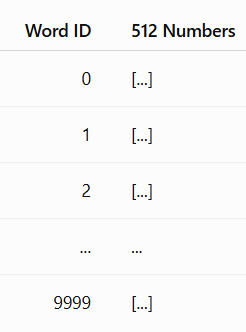

In [103]:
# Creates an embedding layer of size eng_vocab_size * 512  i.e.   for example Embedding(10000, 512)
encoder_embedding = Embedding(eng_vocab_size,512)  # This creates an Embedding layer object. At this point no words have entered the layer.

#In Below line of code

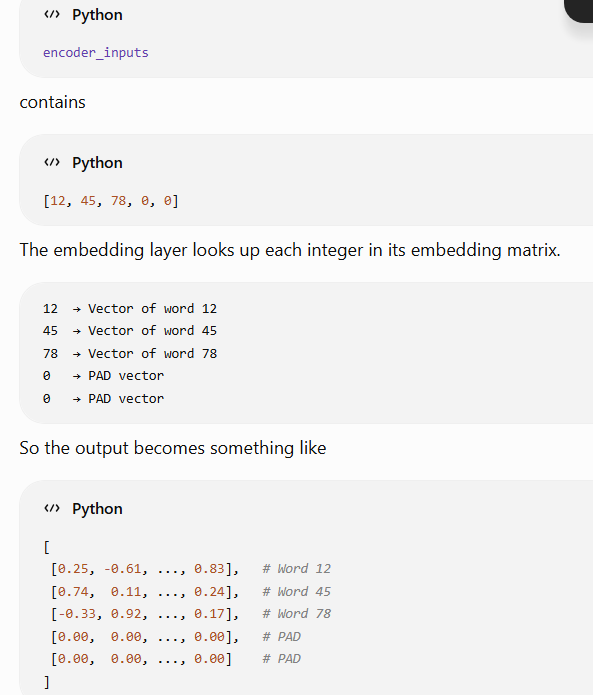

In [104]:
#Feed the Input layer into embedding or we can say connect the encoder_inputs placeholder to the embedding layer.
enc_emb = encoder_embedding(encoder_inputs)

# Create LSTM layer Object

Following code creates an LSTM layer object.

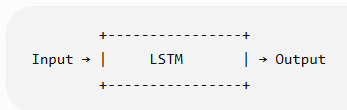

No sentence has entered yet.

In [105]:
enc_lstm = LSTM(512 , return_state=True)

# return_state = True -> After processing the sentence, also give me your final hidden state and final cell state.
# BY default lstm returns only output no states so if we want states then we need to use return_state=True

In above code line : 512 = number of hidden units (neurons) inside the LSTM. It means the LSTM memory has size 512.

Every hidden state (state_h) will have length 512.

Every cell state (state_c) will also have length 512.

So, we get

state_h

[
0.12,
-0.45,
...
512 values
]

state_c

[
0.88,
0.14,
...
512 values
]

In [106]:
# The encoder reads the entire English sentence and produces Hidden State and cell state
encoder_output , state_h , state_c = enc_lstm(enc_emb)  # Now the embedded sentence enters the encoder LSTM.
encoder_states = [state_h,state_c] # Save those states in a list. Also, called as Context Vector

# Step 9 : Decoder Architecture

### Following line of code where the decoder will receive something like following during model training process.

\<sos>

## or

\<sos> Je

## or

\<sos> Je suis

In [107]:
# Remember decoder_input is based french column , created in above mentioned Step 6.
decoder_inputs = Input(shape=(max_len_fre,))

In [108]:
# Creates an embedding layer of size fre_vocab_size * 512  i.e.   for example Embedding(10000, 512)

decoder_embedding = Embedding(fre_vocab_size,512) # This creates an Embedding layer object. At this point no words have entered the layer.


# Feed the Input layer into embedding or we can say connect the decoder_inputs placeholder to the embedding layer.
dec_emb = decoder_embedding(decoder_inputs)   # Word IDs become vectors.

In [109]:
dec_lstm = LSTM(512 , return_state=True,return_sequences=True)

# Above is only one LSTM layer, not multiple LSTM layers. It is the same LSTM cell reused at every time step.
# Each time step of the decoder LSTM produces an output, a hidden state, and a cell state.


# return_state = True. This means at every time step we expect LSTM to produce Output, Hidden state (h) and Cell state (c).
                # Next time step will use this hidden and cell state along with french input to produce next output and next hidden & cell states.
# return_sequences = True . This means The decoder must predict every word and give the respective output. And not just give the last output.
                     #i.e. output at every timestep should be there.


In [110]:
# Connect encoder and decoder.
decoder_output,_,_ = dec_lstm(dec_emb , initial_state=encoder_states)


# initial_state=encoder_states. Usually, an LSTM starts with h0 = 0, c0 = 0, But in Encoder-Decoder, we don't want the decoder to start with empty memory.
# Instead, initial_state=encoder_states means "Decoder h0 = Encoder final hidden state"   and   "Decoder c0 = Encoder final cell state"

# Step 10 : Dense Layer

In [111]:
#Create a Dense layer whose output has fre_vocab_size neurons and apply softmax.

decoder_dense = Dense(fre_vocab_size, activation='softmax') # Does not perform any computation yet. It is just creating (defining) a Dense layer object.

# Pass the data to dense layer

decoder_output = decoder_dense(decoder_output)

# Suppose French vocabulary has 5000 words, Softmax produces Probability of every French word. The highest probability becomes the predicted word.

# Step 11 : Build Training Model

The model has two inputs:

English sentence → Encoder

Shifted French sentence (decoder_input) → Decoder

And one output:

Predicted next French word at every time step.

In [112]:
model = Model([encoder_inputs,decoder_inputs],decoder_output)

In [113]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 7, 512)    │  4,682,752 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 14, 512)   │  8,296,960 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 512),     │  2,099,200 │ embedding_2[0][0] │
│                     │ (None, 512),      │            │                   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, 14, 512), │  2,099,200 │ embedding_3[0][0… │
│                     │ (None, 512),      │            │ lstm_2[0][1],     │
│                     │ (None, 512)]      │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 14, 16205) │  8,313,165 │ lstm_3[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,491,277 (97.24 MB)

 Trainable params: 25,491,277 (97.24 MB)

 Non-trainable params: 0 (0.00 B)

#Step 12 : Compile

preparing the model for training

cross_entropy -> measuring the difference between actual answer and predicted probabilities

In [114]:
model.compile(loss="sparse_categorical_crossentropy",optimizer='adam',metrics=['accuracy'])

# Step 13 : Expand Dimensions

In [115]:
decoder_target.shape

(50000, 14)

In [116]:
import numpy as np
decoder_target = np.expand_dims(decoder_target,axis=-1)

In [117]:
decoder_target.shape

(50000, 14, 1)

# Step 14 : Training

In [118]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [119]:
history = model.fit([encoder_input , decoder_input],decoder_target,batch_size=128,epochs=40,validation_split=0.2,callbacks=[early_stop])

Epoch 1/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 72s 221ms/step - accuracy: 0.7195 - loss: 2.0904 - val_accuracy: 0.6944 - val_loss: 2.0958
Epoch 2/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 71s 227ms/step - accuracy: 0.7738 - loss: 1.4922 - val_accuracy: 0.7399 - val_loss: 1.7994
Epoch 3/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 73s 233ms/step - accuracy: 0.8095 - loss: 1.2125 - val_accuracy: 0.7620 - val_loss: 1.6086
Epoch 4/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 238ms/step - accuracy: 0.8285 - loss: 1.0270 - val_accuracy: 0.7744 - val_loss: 1.5060
Epoch 5/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 75s 240ms/step - accuracy: 0.8425 - loss: 0.8812 - val_accuracy: 0.7832 - val_loss: 1.4377
Epoch 6/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 240ms/step - accuracy: 0.8556 - loss: 0.7545 - val_accuracy: 0.7916 - val_loss: 1.3753
Epoch 7/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 75s 240ms/step - accuracy: 0.8684 - loss: 0.6416 - val_accuracy: 0.7981 - val_loss: 1.3277
Epoch 8/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 75s 240ms/step - accuracy: 0.8820 - loss: 0

In [120]:
eng_tokenizer.word_index.items() # key - values (word , index)

dict_items([('<unk>', 1), ('i', 2), ('you', 3), ('a', 4), ('is', 5), ('tom', 6), ('the', 7), ("i'm", 8), ('to', 9), ('it', 10), ('he', 11), ("you're", 12), ('was', 13), ('do', 14), ('we', 15), ('are', 16), ("don't", 17), ('have', 18), ('my', 19), ('this', 20), ('your', 21), ("it's", 22), ('it.', 23), ('not', 24), ('you.', 25), ('can', 26), ('did', 27), ('be', 28), ('that', 29), ('they', 30), ('me.', 31), ('like', 32), ("we're", 33), ('me', 34), ('what', 35), ('no', 36), ('all', 37), ('very', 38), ("that's", 39), ('she', 40), ('how', 41), ('get', 42), ('go', 43), ('in', 44), ('that.', 45), ("can't", 46), ('need', 47), ("i'll", 48), ('of', 49), ('want', 50), ('tom.', 51), ('on', 52), ('got', 53), ('here.', 54), ('know', 55), ('for', 56), ('just', 57), ("they're", 58), ('were', 59), ('has', 60), ('who', 61), ('so', 62), ('at', 63), ("let's", 64), ('love', 65), ('take', 66), ('this.', 67), ("he's", 68), ('look', 69), ('it?', 70), ('will', 71), ('come', 72), ('one', 73), ('up.', 74), ("didn

In [121]:
eng_index_word = {v:k for k , v in eng_tokenizer.word_index.items()}
fre_index_word = {v:k for k , v in fre_tokenizer.word_index.items()}

In [122]:
eng_index_word

{1: '<unk>',
 2: 'i',
 3: 'you',
 4: 'a',
 5: 'is',
 6: 'tom',
 7: 'the',
 8: "i'm",
 9: 'to',
 10: 'it',
 11: 'he',
 12: "you're",
 13: 'was',
 14: 'do',
 15: 'we',
 16: 'are',
 17: "don't",
 18: 'have',
 19: 'my',
 20: 'this',
 21: 'your',
 22: "it's",
 23: 'it.',
 24: 'not',
 25: 'you.',
 26: 'can',
 27: 'did',
 28: 'be',
 29: 'that',
 30: 'they',
 31: 'me.',
 32: 'like',
 33: "we're",
 34: 'me',
 35: 'what',
 36: 'no',
 37: 'all',
 38: 'very',
 39: "that's",
 40: 'she',
 41: 'how',
 42: 'get',
 43: 'go',
 44: 'in',
 45: 'that.',
 46: "can't",
 47: 'need',
 48: "i'll",
 49: 'of',
 50: 'want',
 51: 'tom.',
 52: 'on',
 53: 'got',
 54: 'here.',
 55: 'know',
 56: 'for',
 57: 'just',
 58: "they're",
 59: 'were',
 60: 'has',
 61: 'who',
 62: 'so',
 63: 'at',
 64: "let's",
 65: 'love',
 66: 'take',
 67: 'this.',
 68: "he's",
 69: 'look',
 70: 'it?',
 71: 'will',
 72: 'come',
 73: 'one',
 74: 'up.',
 75: "didn't",
 76: 'too',
 77: 'let',
 78: 'had',
 79: 'why',
 80: 'go.',
 81: 'see',
 82: 

In [123]:
def translate_Sentence(sentence):

  # encoder input
  seq = eng_tokenizer.texts_to_sequences([sentence])
  seq = pad_sequences(seq,maxlen=max_len_eng,padding='post')

  # decoder -> <start> and <end>
  start_token = fre_tokenizer.word_index["<sos>"]
  end_token = fre_tokenizer.word_index["<eos>"]

  decoder_sequence = [start_token]

  translated_sent = [] # will store translated words

  for i in range(max_len_fre):
    decoder_input = pad_sequences([decoder_sequence],maxlen=max_len_fre , padding='post')
    prediction = model.predict([seq,decoder_input], verbose=0)
    next_word_id = np.argmax(prediction[0,len(decoder_sequence)-1])

    if next_word_id == end_token:
      break

    if next_word_id == 0:
      break

    translated_sent.append(fre_index_word[next_word_id])
    decoder_sequence.append(next_word_id)

  return " ".join(translated_sent)

In [124]:
print(translate_Sentence("I know english"))

je sais que j'ai des choses.


In [125]:
print(translate_Sentence("Hello."))
print(translate_Sentence("Go."))
print(translate_Sentence("I know."))

bonjour.
en route !
je le réparai.


In [126]:
print("Final Training Loss     :", history.history['loss'][-1])
print("Final Training Accuracy :", history.history['accuracy'][-1])
print("Final Validation Loss   :", history.history['val_loss'][-1])
print("Final Validation Accuracy:", history.history['val_accuracy'][-1])

Final Training Loss     : 0.17381072044372559
Final Training Accuracy : 0.947655439376831
Final Validation Loss   : 1.2988814115524292
Final Validation Accuracy: 0.8173141479492188


In [66]:
#following for old code version where parameters were little different.
#such as without oov, with 10000 instead of 50000,

print("Final Training Loss     :", history.history['loss'][-1])
print("Final Training Accuracy :", history.history['accuracy'][-1])
print("Final Validation Loss   :", history.history['val_loss'][-1])
print("Final Validation Accuracy:", history.history['val_accuracy'][-1])

Final Training Loss     : 0.3127247095108032
Final Training Accuracy : 0.9145417809486389
Final Validation Loss   : 1.558693766593933
Final Validation Accuracy: 0.8159583806991577


In [127]:
print(translate_Sentence("I am learning AI"))

je suis sous la choc.


In [128]:
print(translate_Sentence("I am ill."))
print(translate_Sentence("I am sad."))
print(translate_Sentence("I am shy."))
print(translate_Sentence("I know."))
print(translate_Sentence("Help me."))
print(translate_Sentence("Go."))

je suis malade.
je suis triste.
je suis timide.
je le réparai.
aide-moi !
en route !


In [129]:
from tensorflow.keras.models import load_model

model.save(r"C:\english_french_seq2seq.keras")

In [130]:
import pickle

with open(r"C:\eng_tokenizer.pkl", "wb") as f:
    pickle.dump(eng_tokenizer, f)

with open(r"C:\fre_tokenizer.pkl", "wb") as f:
    pickle.dump(fre_tokenizer, f)